In [37]:
%pip install -U duckduckgo_search

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
C:\Users\Vidhy\AppData\Roaming\Python\Python312\site-packages\IPython\utils\_process_win32.py:131: ResourceWarning: unclosed file <_io.BufferedWriter name=3>
  res = process_handler(cmd, _system_body)
C:\Users\Vidhy\AppData\Roaming\Python\Python312\site-packages\IPython\utils\_process_win32.py:131: ResourceWarning: unclosed file <_io.BufferedReader name=4>
  res = process_handler(cmd, _system_body)
C:\Users\Vidhy\AppData\Roaming\Python\Python312\site-packages\IPython\utils\_process_win32.py:131: ResourceWarning: unclosed file <_io.BufferedReader name=5>
  res = process_handler(cmd, _system_body)


In [38]:
%pip install -U ddgs


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
C:\Users\Vidhy\AppData\Roaming\Python\Python312\site-packages\IPython\utils\_process_win32.py:131: ResourceWarning: unclosed file <_io.BufferedWriter name=3>
  res = process_handler(cmd, _system_body)
C:\Users\Vidhy\AppData\Roaming\Python\Python312\site-packages\IPython\utils\_process_win32.py:131: ResourceWarning: unclosed file <_io.BufferedReader name=4>
  res = process_handler(cmd, _system_body)
C:\Users\Vidhy\AppData\Roaming\Python\Python312\site-packages\IPython\utils\_process_win32.py:131: ResourceWarning: unclosed file <_io.BufferedReader name=5>
  res = process_handler(cmd, _system_body)


In [39]:
import time
from fastcore.all import *
from ddgs import DDGS

def search_images(term, max_images=30, retries=3):
    print(f"Searching for '{term}'")
    for attempt in range(retries):
        try:
            with DDGS() as ddgs:
                results = list(ddgs.images(keywords=term, max_results=max_images))
                return L(results).itemgot('image')
        except Exception as e:
            print(f"Rate limited or failed (attempt {attempt+1}/{retries}), waiting 3s...")
            time.sleep(3)
    return L()


In [40]:
urls = search_images('bird photos', max_images=1)
urls[0]


Searching for 'bird photos'
Rate limited or failed (attempt 1/3), waiting 3s...
Rate limited or failed (attempt 2/3), waiting 3s...


KeyboardInterrupt: 

In [ ]:
urls = search_images('bird photos', max_images=1)
urls[0]


Searching for 'bird photos'


C:\Users\Vidhy\AppData\Local\Temp\ipykernel_19832\2826244709.py:3: RuntimeWarning: This package (`duckduckgo_search`) has been renamed to `ddgs`! Use `pip install ddgs` instead.
  with DDGS() as ddgs:


RatelimitException: https://duckduckgo.com/i.js?o=json&q=bird+photos&l=us-en&vqd=4-114740509142378945068477624550515528355&p=1&f=%2C%2C%2C%2C%2C 403 Ratelimit

In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.0+cu126
CUDA: 12.6
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [ ]:
path = Path('chapter2/bear-image-classifier')


In [44]:
path

Path('chapter2/bear-image-classifier')

In [ ]:
from fastai.data.transforms import get_image_files
fns = get_image_files(path)

In [41]:
from fastai.vision.all import *
bears = DataBlock(
 blocks=(ImageBlock, CategoryBlock),
 get_items=get_image_files,
 splitter=RandomSplitter(valid_pct=0.2, seed=42),
 get_y=parent_label,
 item_tfms=Resize(128))

c:\Users\Vidhy\AppData\Local\Programs\Python\Python312\Lib\site-packages\matplotlib\cbook.py:713: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  x = np.array(x, subok=True, copy=copy)
c:\Users\Vidhy\AppData\Local\Programs\Python\Python312\Lib\site-packages\matplotlib\cbook.py:713: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  x = np.array(x, subok=True, copy=copy)
c:\Users\Vidhy\AppData\Local\Programs\Python\Python312\Lib\site-packages\matplotlib\cbook.py:713: DeprecationWar

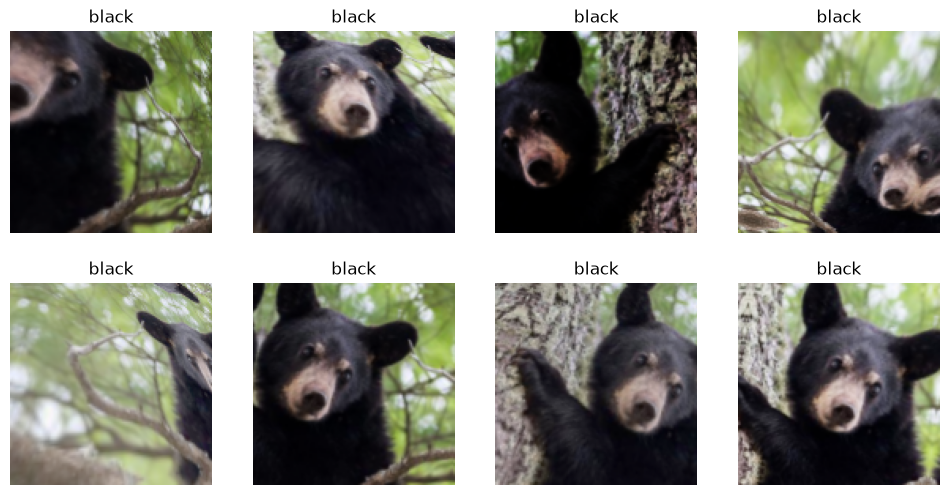

In [ ]:
bears = bears.new(item_tfms=Resize(128), batch_tfms=aug_transforms(mult=2))
dls = bears.dataloaders(path)


c:\Users\Vidhy\AppData\Local\Programs\Python\Python312\Lib\site-packages\matplotlib\cbook.py:713: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  x = np.array(x, subok=True, copy=copy)
c:\Users\Vidhy\AppData\Local\Programs\Python\Python312\Lib\site-packages\matplotlib\cbook.py:713: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  x = np.array(x, subok=True, copy=copy)
c:\Users\Vidhy\AppData\Local\Programs\Python\Python312\Lib\site-packages\matplotlib\cbook.py:713: DeprecationWar

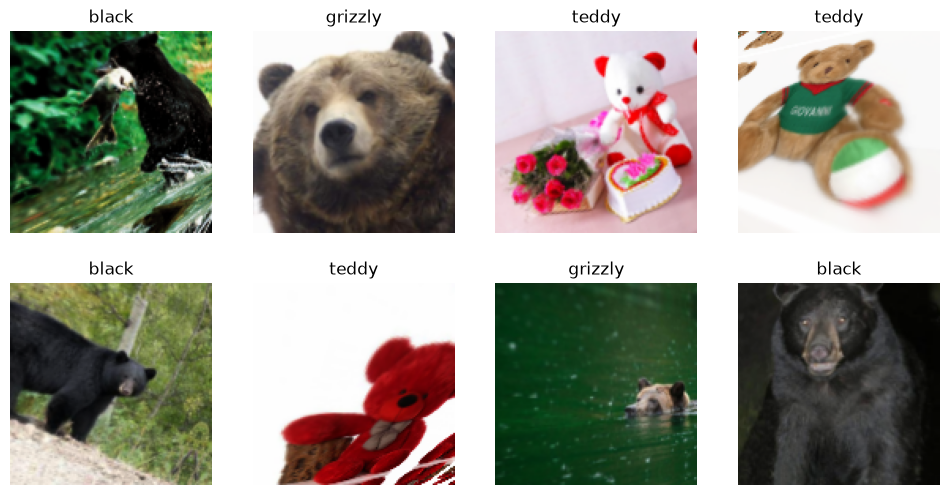

In [50]:
dls.train.show_batch(max_n=8, nrows=2, unique=False)

In [52]:
learn = vision_learner(dls, resnet18, metrics=error_rate)
learn.fine_tune(10)

epoch,train_loss,valid_loss,error_rate,time
0,1.442226,0.244377,0.057692,00:02


epoch,train_loss,valid_loss,error_rate,time
0,0.355981,0.259341,0.057692,00:03
1,0.328311,0.304942,0.057692,00:03
2,0.282035,0.338934,0.057692,00:03
3,0.266621,0.397978,0.057692,00:03
4,0.245290,0.271753,0.038462,00:02
5,0.217728,0.275309,0.038462,00:02
6,0.200945,0.337496,0.048077,00:02
7,0.188838,0.320633,0.048077,00:02
8,0.176398,0.303797,0.038462,00:02
9,0.171891,0.290410,0.038462,00:02


In [53]:
interp = ClassificationInterpretation.from_learner(learn)

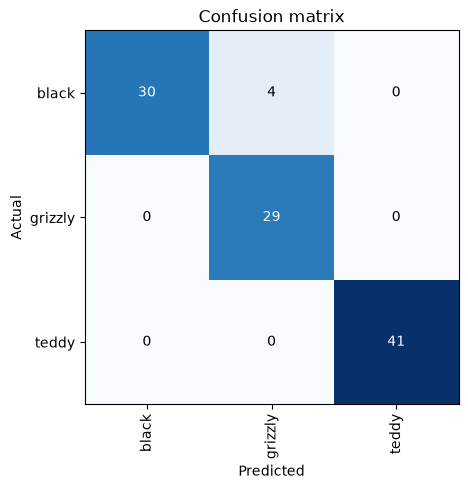

In [54]:
interp.plot_confusion_matrix()

<div><progress max="1" value="0"></progress> 0.00% [0/1 00:00&lt;?]</div>

c:\Users\Vidhy\AppData\Local\Programs\Python\Python312\Lib\site-packages\matplotlib\cbook.py:713: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  x = np.array(x, subok=True, copy=copy)
c:\Users\Vidhy\AppData\Local\Programs\Python\Python312\Lib\site-packages\matplotlib\cbook.py:713: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  x = np.array(x, subok=True, copy=copy)
c:\Users\Vidhy\AppData\Local\Programs\Python\Python312\Lib\site-packages\matplotlib\cbook.py:713: DeprecationWar

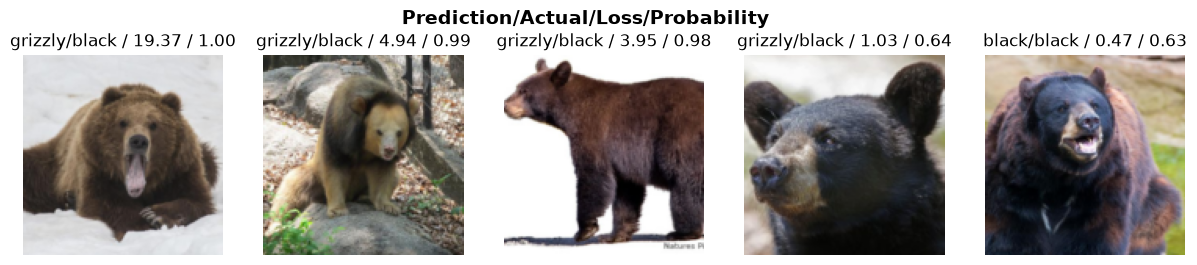

In [56]:
interp.plot_top_losses(5, nrows=1)

In [60]:
from pathlib import Path

Path.cwd()

Path('c:/NIT KKR/after placement/fast ai/chapter workings')

In [61]:
Path.cwd().ls()

[Path('c:/NIT KKR/after placement/fast ai/chapter workings/bears'), Path('c:/NIT KKR/after placement/fast ai/chapter workings/chapter2'), Path('c:/NIT KKR/after placement/fast ai/chapter workings/chapter2.ipynb'), Path('c:/NIT KKR/after placement/fast ai/chapter workings/classify.ipynb'), Path('c:/NIT KKR/after placement/fast ai/chapter workings/export.pkl'), Path('c:/NIT KKR/after placement/fast ai/chapter workings/trial.ipynb')]

In [62]:
Path('export.pkl').exists()

True

In [3]:
path = Path('c:/NIT KKR/after placement/fast ai/chapter workings')
path.exists()

True

In [73]:
learn.export()

In [7]:
learn_inf = load_learner(path/'BEAR_CLASSIFY.pkl')
# C:\NIT KKR\after placement\fast ai\chapter workings\BEAR_CLASSIFY.pkl

In [8]:
learn_inf.predict('chapter2/bear-image-classifier/black/00000022.jpg')
# Output: ('grizzly', tensor(1), tensor([9.0767e-06, 9.9999e-01, 1.5748e-07]))

('black', tensor(0), tensor([9.9927e-01, 3.8307e-04, 3.4952e-04]))

In [84]:
%pip install -U ipywidgets

   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   --------- ------------------------------ 0.5/2.2 MB 2.1 MB/s eta 0:00:01
   ----------------------- ---------------- 1.3/2.2 MB 3.5 MB/s eta 0:00:01
   ---------------------------------------- 2.2/2.2 MB 3.6 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
C:\Users\Vidhy\AppData\Roaming\Python\Python312\site-packages\IPython\utils\_process_win32.py:131: ResourceWarning: unclosed file <_io.BufferedWriter name=7>
  res = process_handler(cmd, _system_body)
C:\Users\Vidhy\AppData\Roaming\Python\Python312\site-packages\IPython\utils\_process_win32.py:131: ResourceWarning: unclosed file <_io.BufferedReader name=8>
  res = process_handler(cmd, _system_body)
C:\Users\Vidhy\AppData\Roaming\Python\Python312\site-packages\IPython\utils\_process_win32.py:131: ResourceWarning: unclosed file <_io.BufferedReader name=9>
  res = process_handler(cmd, _system_body)


In [94]:
import ipywidgets as widgets
from fastai.vision.all import *

btn_upload = widgets.FileUpload(accept='image/*')
btn_upload

FileUpload(value=(), accept='image/*', description='Upload')

In [ ]:
import ipywidgets as widgets
from IPython.display import display
from fastai.vision.all import *

btn_upload = widgets.FileUpload(accept='image/*')

out_pl = widgets.Output()

lbl_pred = widgets.Label()

btn_run = widgets.Button(description='Classify')


def on_click_classify(change):
    img = PILImage.create(bytes(btn_upload.value[0]['content']))

    out_pl.clear_output()

    with out_pl:
        display(img.to_thumb(128, 128))

    pred, pred_idx, probs = learn_inf.predict(img)

    lbl_pred.value = f'Prediction: {pred}; Probability: {probs[pred_idx]:.04f}'


btn_run.on_click(on_click_classify)

widgets.VBox([
    widgets.Label('Select your bear!'),
    btn_upload,
    btn_run,
    out_pl,
    lbl_pred
])